# CardioIA — Fase 6 | Modelo Preditivo de Pico de Risco

**FIAP | Atividade acadêmica — Base sintética**

Este notebook reproduz a geração dos **5.000 registros sintéticos** do enunciado, treinamento supervisionado, separação treino/teste, avaliação, persistência do modelo e simulação de um novo caso. O arquivo salvo é utilizado pelo **Agente Analista de Risco** no sistema multiagente.

> **Aviso:** os dados e rótulos são construídos por regras artificiais. Resultados elevados não representam capacidade preditiva clínica nem autorização para recomendar condutas médicas reais.

**Execução:** no Google Colab, clique em `Ambiente de execução → Executar tudo`. As dependências principais normalmente já estão presentes no ambiente Colab.

## 1. Bibliotecas e configuração

Usaremos NumPy e Pandas para os dados, Scikit-learn para o Random Forest e métricas, Joblib para salvar o modelo, e Matplotlib para a matriz de confusão.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, confusion_matrix,
                             f1_score, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import train_test_split

SEMENTE = 42
N_REGISTROS = 5000
FEATURES = [
    "idade_media", "carga_sistema", "tempo_espera", "fc_media",
    "spo2_media", "pa_sistolica", "temperatura", "densidade_eventos",
    "eventos_24h", "disponibilidade_recursos",
]

print("Bibliotecas carregadas. Semente:", SEMENTE)

Bibliotecas carregadas. Semente: 42


## 2. Geração da base sintética

Reproduzimos o mecanismo original indicado no enunciado, incluindo as seis condições que compõem `risk_score`. A classe `pico_risco` recebe valor **1** quando ao menos duas dessas condições são verdadeiras; caso contrário, **0**.

In [2]:
np.random.seed(SEMENTE)
n = N_REGISTROS

df = pd.DataFrame({
    "idade_media": np.random.normal(55, 12, n).clip(18, 90),
    "carga_sistema": np.random.uniform(30, 100, n),
    "tempo_espera": np.random.normal(45, 20, n).clip(5, 180),
    "fc_media": np.random.normal(85, 15, n).clip(50, 150),
    "spo2_media": np.random.normal(95, 3, n).clip(70, 100),
    "pa_sistolica": np.random.normal(125, 20, n).clip(80, 200),
    "temperatura": np.random.normal(24, 5, n).clip(10, 40),
    "densidade_eventos": np.random.poisson(3, n),
    "eventos_24h": np.random.poisson(2, n),
    "disponibilidade_recursos": np.random.uniform(20, 100, n),
})

risk_score = (
    (df["carga_sistema"] > 80).astype(int)
    + (df["tempo_espera"] > 60).astype(int)
    + (df["spo2_media"] < 92).astype(int)
    + (df["fc_media"] > 110).astype(int)
    + (df["eventos_24h"] > 4).astype(int)
    + (df["disponibilidade_recursos"] < 40).astype(int)
)
df["pico_risco"] = (risk_score >= 2).astype(int)

assert len(df) == N_REGISTROS
assert not df[FEATURES + ["pico_risco"]].isna().any().any()
print("Registros gerados:", len(df))
print("Distribuição das classes:")
display(df["pico_risco"].value_counts().rename_axis("classe").to_frame("quantidade"))
display(df.head())

Registros gerados: 5000
Distribuição das classes:


,quantidade
classe,
0,3671
1,1329


,idade_media,carga_sistema,tempo_espera,fc_media,spo2_media,pa_sistolica,temperatura,densidade_eventos,eventos_24h,disponibilidade_recursos,pico_risco
0,60.960570,41.776561,26.230658,111.709579,92.960100,131.711117,25.449200,1,2,35.486591,1
1,53.340828,43.295432,34.071848,112.443439,96.509986,81.160294,18.040015,4,1,82.232538,0
2,62.772262,62.249852,39.355188,76.369939,94.709752,163.880966,19.905007,6,0,88.160917,0
3,73.276358,50.039590,66.015486,88.797755,93.714735,131.224152,28.616685,2,2,89.771810,0
4,52.190160,47.322409,21.741220,63.560997,95.784214,138.439755,33.384496,4,0,62.786630,0


## 3. Preparação dos dados e divisão treino/teste

Separamos 80% da amostra para treinamento e 20% para teste. A estratificação (`stratify=y`) preserva aproximadamente a proporção das classes nos dois conjuntos. As variáveis de entrada são as dez colunas previstas no enunciado; a variável-alvo é `pico_risco`.

In [3]:
X = df[FEATURES]
y = df["pico_risco"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=SEMENTE, stratify=y
)

print(f"Treino: {len(X_treino)} registros | Teste: {len(X_teste)} registros")
print("Proporção da classe positiva: treino =", round(y_treino.mean(), 4),
      "teste =", round(y_teste.mean(), 4))

Treino: 4000 registros | Teste: 1000 registros
Proporção da classe positiva: treino = 0.2658 teste = 0.266


## 4. Treinamento do classificador

O **Random Forest** combina múltiplas árvores de decisão e captura relações não lineares entre as variáveis. São usados os mesmos hiperparâmetros do `main.py` do projeto para manter os resultados coerentes.

In [4]:
modelo = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    random_state=SEMENTE,
)
modelo.fit(X_treino, y_treino)
print("Modelo treinado:", type(modelo).__name__)

Modelo treinado: RandomForestClassifier


## 5. Avaliação: acurácia, precisão, recall, F1 e matriz de confusão

A matriz é organizada com as **classes reais nas linhas** e as **previstas nas colunas**. Em aplicações sensíveis a falso negativo, o recall da classe positiva merece atenção. Entretanto, este estudo tem finalidade **exclusivamente acadêmica**.

,Métrica,Valor
0,Acurácia,0.9990
1,Precisão,1.0000
2,Recall,0.9962
3,F1-score,0.9981
4,ROC-AUC,1.0000


Matriz de confusão:
 [[734   0]
 [  1 265]]

Relatório de classificação:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       734
           1       1.00      1.00      1.00       266

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



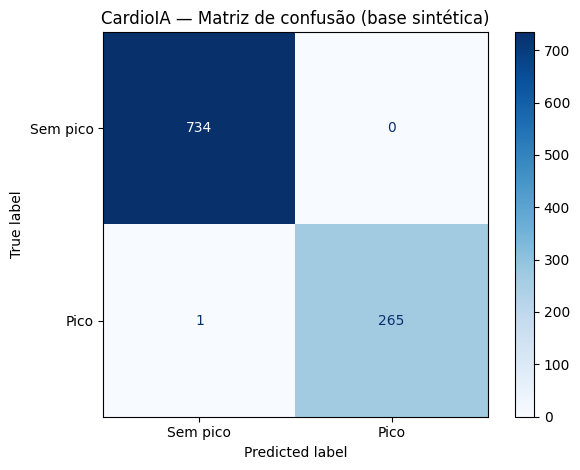

In [5]:
y_pred = modelo.predict(X_teste)
y_prob = modelo.predict_proba(X_teste)[:, 1]
matriz = confusion_matrix(y_teste, y_pred, labels=[0, 1])

metricas = {
    "total_registros": int(len(df)),
    "registros_treino": int(len(X_treino)),
    "registros_teste": int(len(X_teste)),
    "acuracia": float(accuracy_score(y_teste, y_pred)),
    "precisao": float(precision_score(y_teste, y_pred, zero_division=0)),
    "recall": float(recall_score(y_teste, y_pred, zero_division=0)),
    "f1_score": float(f1_score(y_teste, y_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_teste, y_prob)),
    "matriz_confusao": matriz.tolist(),
}

display(pd.DataFrame({
    "Métrica": ["Acurácia", "Precisão", "Recall", "F1-score", "ROC-AUC"],
    "Valor": [metricas[k] for k in ["acuracia", "precisao", "recall", "f1_score", "roc_auc"]],
}).style.format({"Valor": "{:.4f}"}))

print("Matriz de confusão:\n", matriz)
print("\nRelatório de classificação:\n")
print(classification_report(y_teste, y_pred, zero_division=0))

display_grafico = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=["Sem pico", "Pico"])
display_grafico.plot(cmap="Blues", values_format="d")
plt.title("CardioIA — Matriz de confusão (base sintética)")
plt.tight_layout()
plt.show()

## 6. Salvamento do modelo e métricas

O notebook gera os arquivos na pasta `artefatos_colab/`. Para integrá-los ao repositório, copie `modelo_risco_cardiaco.pkl` para a pasta `agents/` do projeto. **Não execute arquivos `.pkl` de origens desconhecidas**.

O sistema multiagente local já utiliza `agents/modelo_risco_cardiaco.pkl`; só substitua esse modelo se desejar usar o artefato recriado no Colab, mantendo as mesmas versões das dependências.

In [6]:
pasta_saida = Path("artefatos_colab")
pasta_saida.mkdir(exist_ok=True)

arquivo_modelo = pasta_saida / "modelo_risco_cardiaco.pkl"
arquivo_metricas = pasta_saida / "metricas_modelo.json"

joblib.dump(modelo, arquivo_modelo)
arquivo_metricas.write_text(
    json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Modelo salvo em:", arquivo_modelo)
print("Métricas salvas em:", arquivo_metricas)

Modelo salvo em: artefatos_colab/modelo_risco_cardiaco.pkl
Métricas salvas em: artefatos_colab/metricas_modelo.json


## 7. Simulação de previsão para um novo caso

Os valores reproduzem o caso do enunciado. Foi corrigido o nome da última coluna para `disponibilidade_recursos` (com sublinhado), conforme a base de treinamento. Para validar persistência, a previsão usa o modelo **recarregado do arquivo salvo**.

In [7]:
novo_caso = pd.DataFrame([{
    "idade_media": 62,
    "carga_sistema": 92,
    "tempo_espera": 75,
    "fc_media": 118,
    "spo2_media": 89,
    "pa_sistolica": 100,
    "temperatura": 37.5,
    "densidade_eventos": 7,
    "eventos_24h": 5,
    "disponibilidade_recursos": 25,
}])

modelo_carregado = joblib.load(arquivo_modelo)
probabilidade = float(modelo_carregado.predict_proba(novo_caso[FEATURES])[0, 1])
classe = int(modelo_carregado.predict(novo_caso[FEATURES])[0])
rotulo = "PICO DE RISCO" if classe == 1 else "SEM PICO DE RISCO"

print(f"Probabilidade prevista: {probabilidade:.4f} ({probabilidade:.2%})")
print(f"Classe prevista: {classe} — {rotulo}")
print("Aviso: saída simulada para demonstração acadêmica, sem validação clínica.")

Probabilidade prevista: 1.0000 (100.00%)
Classe prevista: 1 — PICO DE RISCO
Aviso: saída simulada para demonstração acadêmica, sem validação clínica.


## 8. Interpretação e limitações

- O projeto formula **classificação binária**: 0 (sem pico) ou 1 (pico). A probabilidade apresentada vem de `predict_proba`, não de um escore clínico validado.
- Os rótulos foram criados **deterministicamente a partir de seis regras** aplicadas às próprias variáveis de entrada; por isso o excelente desempenho é esperado e não deve ser extrapolado para dados reais.
- O conjunto não representa populações, sensores ou desfechos clínicos reais. Não foram realizadas validação externa, análise de vieses nem calibração probabilística.
- Evoluções possíveis: revisão dos critérios por especialistas, validação externa, análise de desbalanceamento, calibração, explicabilidade e avaliação de desempenho ao longo do tempo.

**Integração com a Parte 2:** o Agente Analista de Risco usa o modelo salvo, o Especialista em Protocolos aplica as dez regras simuladas, e o Planejador consolida uma saída estruturada por meio do Orquestrador e seus handoffs. A execução efetiva desses agentes é demonstrada no código Python do repositório, não neste notebook.